# Defensive layer

Bad, tough economic times happen. This basket is designed to find the best way of managing situations. The first thing is to build a trigger which determines when bad times are either coming, or here already, and then decide what to hold when the trigger goes off.

## Imports

In [ ]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Trigger dates

The trigger is constructed privately using general economic data. These are the times the trigger fired, and when the same trigger 'ended', or rather, when the re-entry trigger fired.

In [2]:
sp.table("trigger_spells.csv").set_index("spell")

,first_defensive_month,last_defensive_month,re_entry_month,months_defensive,open_at_window_start
spell,,,,,
1,2001-02,2002-12,2003-01,23,True
2,2008-05,2008-05,2008-06,1,False
3,2008-07,2009-07,2009-08,13,False
4,2010-07,2010-07,2010-08,1,False
5,2020-04,2020-06,2020-07,3,False


We can see that the trigger had a false re-entry in 2008, before swiftly re-entering the defensive basket. Moreover, it had a 'false-alarm' in 2010, during the Euro crisis.

## 2001-2026



Now, with the basket chosen to a collection of safe, reliable, defensive assets, I then combined the trigger, defensive basket, and the core to get the following equity curve.

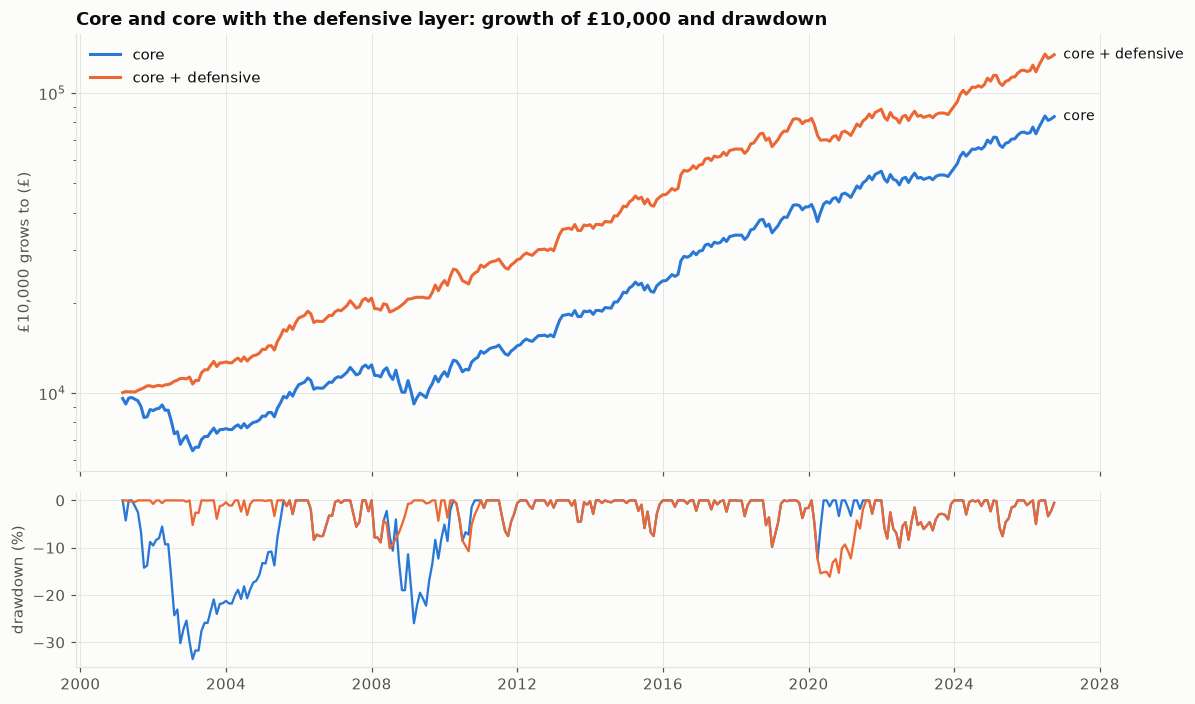

In [3]:
cd = d["core"] + d["defensive"]
sp.curves({"core": d["core"], "core + defensive": cd}, {"core": sp.COLORS["core"], "core + defensive": sp.COLORS["defensive"]}, "Core and core with the defensive layer: growth of £10,000 and drawdown")

The core+defensive basket has not only better performance over the time, but also lower drawdown everywhere apart from the later defensive entry in 2020, and the false alarm in 2010. The one area this basket is weak is the 2020 recession, due to the speed at which the market crashed, and reacted so quickly, leading the trigger to almost be reacting too slowly in both directions.

## Summary

In [4]:
sp.table("layers_stats.csv").query("layers in ['core', 'core + defensive']").set_index(["window", "layers"]).sort_index()

months  sharpe  cagr_pct  vol_pct  max_drawdown_pct  final_gbp_from_10k
window               layers                                                                                   
2001-05              core                  59  -0.159     1.351   13.329           -35.685          10,682.249
                     core + defensive      59   0.964    12.477    8.076            -5.207          17,826.621
2006-13              core                  96   0.441     7.339   13.010           -25.956          17,622.767
                     core + defensive      96   0.722     9.349   10.072           -10.751          20,442.132
2014-19              core                  72   1.333    14.212   10.008            -9.812          22,196.154
                     core + defensive      72   1.333    14.212   10.008            -9.812          22,196.154
2020-26              core                  81   0.724    10.805   11.279           -12.309          19,987.885
                     core + defensive      81   0.495     7.806   10.830           -16.120          16,609.001
book 2006-01–2026-09 core                 249   0.750    10.419   11.635           -25.956          78,184.142
                     core + defensive     249   0.815    10.223   10.308           -16.120          75,361.137
full 2001-02–2026-09 core                 308   0.553     8.621   12.018           -35.685          83,518.243
                     core + defensive     308   0.836    10.651    9.908           -16.120         134,343.440

The discussion above about the 2020 crash can be see in the stats table above, with the defensive basket underperforming the core in 2020 due to being too slow to react to both the crash, and the rebound.

## Defensive periods

Lets compared my chosen defensive basket against the core in the same period. 

In [5]:
display(sp.table("defensive_by_spell.csv").set_index("spell"))
sp.table("defensive_pooled.csv").set_index("series")

,first_defensive_month,months,core_return_pct,core_plus_defensive_return_pct,difference_pp
spell,,,,,
1,2001-02,23,-32.153,13.224,45.377
2,2008-05,1,2.134,-0.715,-2.849
3,2008-07,13,-10.090,11.449,21.539
4,2010-07,1,1.926,-1.264,-3.190
5,2020-04,3,16.598,-3.192,-19.789


,months,sharpe,cagr_pct,vol_pct,max_drawdown_pct,final_gbp_from_10k
series,,,,,,
core,41,-0.568,-8.420,18.502,-44.458,"7,404.286"
core + defensive,41,0.566,5.417,3.444,-5.227,"11,975.263"


See that the difference comes from successfully avoiding the two long recessions over the time period (2001, 2008), and the false alarms/late entries are things that count against us. The primary source of losses come from the late entry/exit in 2020 as already discussed.